# Лабораторная 1. Яркость и контраст
Исходный снимок sar_1_gray.jpg взят из материалов [первого задания](https://github.com/Kate-Nits/IMAGE_PROCESSING/tree/main/first_lab). В Colab снимок загружается автоматически.

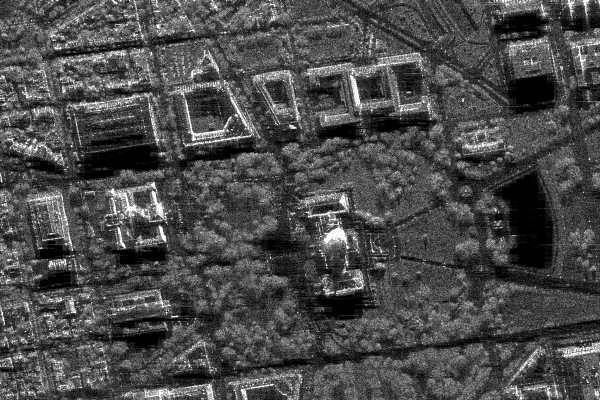

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

path = Path("sar_1_gray.jpg")
if not path.exists():
    path = Path("first_lab/sar_1_gray.jpg")
if not path.exists():
    path = Path("sar_1_gray.jpg")
    urlretrieve("https://raw.githubusercontent.com/GEVORGTERMINATOR/-/main/first_lab/sar_1_gray.jpg", path)
x = np.asarray(Image.open(path).convert("L"))
display(Image.fromarray(x))

## Распределение яркости
По горизонтали — уровни от 0 до 255, по вертикали — число пикселей. Высота самого высокого столбца указана под графиком.

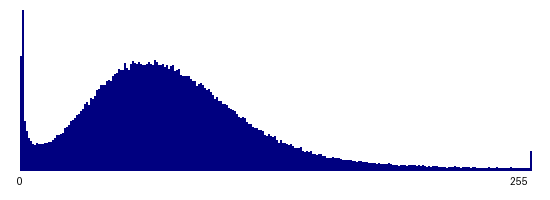

Максимум: 3786 пикселей на уровне 1.


In [2]:
hist = np.bincount(x.ravel(), minlength=256)
chart = Image.new('RGB', (550, 200), 'white')
pen = ImageDraw.Draw(chart)
for level, count in enumerate(hist):
    left = 20 + 2 * level
    height = round(160 * count / hist.max())
    pen.rectangle((left, 170-height, left+1, 170), fill='navy')
pen.text((17, 175), '0', fill='black')
pen.text((510, 175), '255', fill='black')
display(chart)
print(f'Максимум: {hist.max()} пикселей на уровне {hist.argmax()}.')

## Гамма-коррекция и сравнение с оригиналом
Считаем MSE по всем пикселям, SSIM — по скользящим окнам 7×7 с выборочными дисперсиями и усреднением по валидной области.

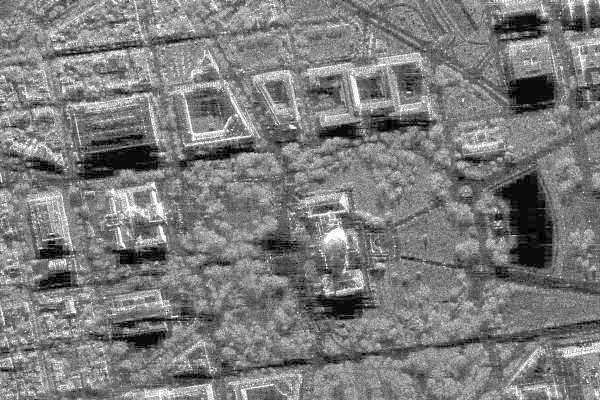

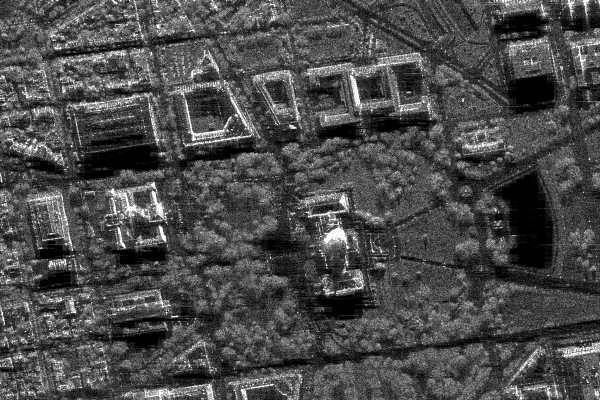

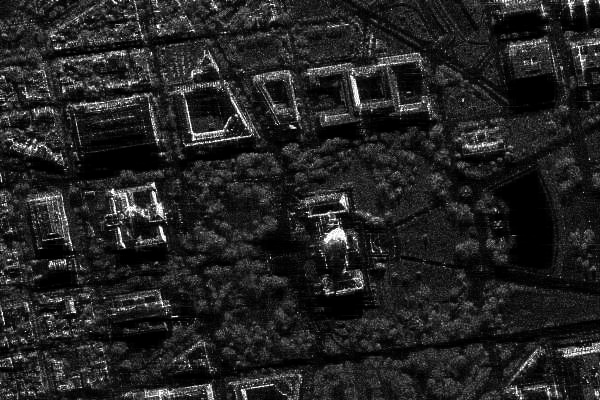

γ=0.55   MSE=2484.36   SSIM=0.8197   средняя яркость=123.5
γ=1.00   MSE=0.00   SSIM=1.0000   средняя яркость=74.9
γ=1.80   MSE=1793.44   SSIM=0.6415   средняя яркость=35.0


In [3]:
def local_mean(a, size=7):
    sums = np.pad(a, ((1, 0), (1, 0))).cumsum(0).cumsum(1)
    return (sums[size:, size:] - sums[:-size, size:] -
            sums[size:, :-size] + sums[:-size, :-size]) / size**2

def metrics(original, changed):
    a, b = original.astype(float), changed.astype(float)
    m, n = local_mean(a), local_mean(b)
    va = (local_mean(a*a) - m*m) * 49/48
    vb = (local_mean(b*b) - n*n) * 49/48
    cov = (local_mean(a*b) - m*n) * 49/48
    c1, c2 = (0.01*255)**2, (0.03*255)**2
    similarity = ((2*m*n+c1)*(2*cov+c2)) / ((m*m+n*n+c1)*(va+vb+c2))
    return np.mean((a-b)**2), similarity.mean()

for gamma in (0.55, 1.0, 1.8):
    changed = np.rint(255 * (x/255)**gamma).astype('uint8')
    mse, ssim = metrics(x, changed)
    print(f'γ={gamma:.2f}   MSE={mse:.2f}   SSIM={ssim:.4f}   средняя яркость={changed.mean():.1f}')
    display(Image.fromarray(changed))

## Статистическая коррекция
Сначала выравниваем гистограмму. Затем используем среднюю яркость и стандартное отклонение выровненного снимка как целевые значения для линейного преобразования оригинала.

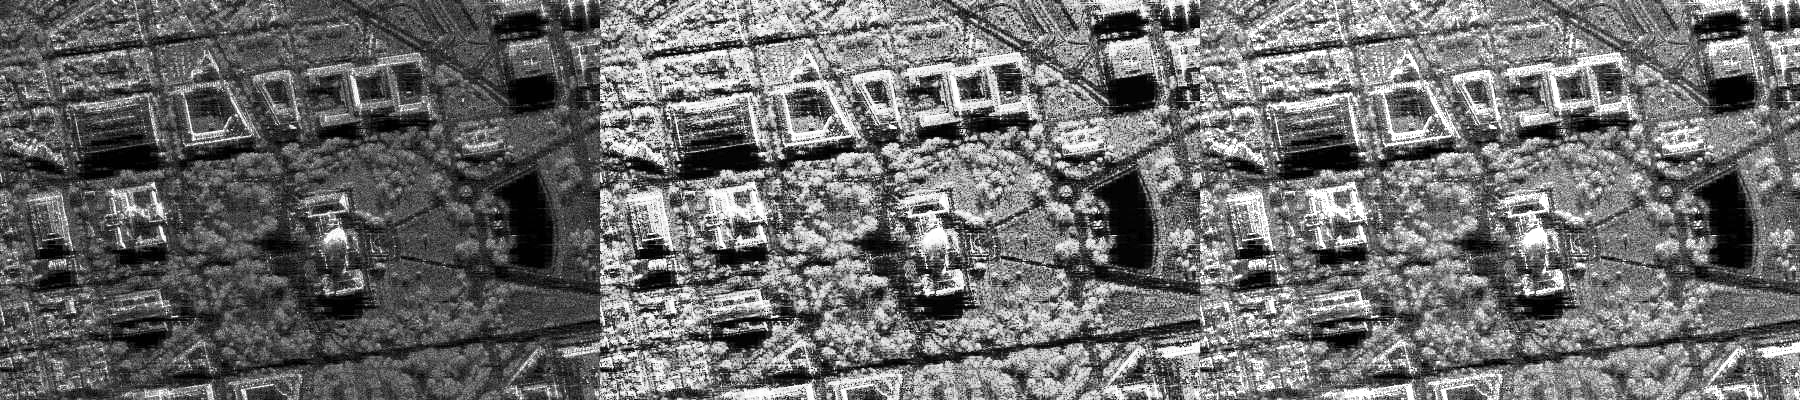

Оригинал: среднее 74.9, стандартное отклонение 43.7
Эквализация: среднее 127.0, стандартное отклонение 74.3
Коррекция: среднее 123.6, стандартное отклонение 65.3


In [4]:
cdf = hist.cumsum()
start = cdf[hist > 0][0]
eq = x.copy()
if x.size > start:
    lut = np.rint(255 * (cdf-start) / (x.size-start)).clip(0,255).astype('uint8')
    eq = lut[x]
adjusted = x.copy()
if x.std() > 0:
    values = (x-x.mean()) * eq.std()/x.std() + eq.mean()
    adjusted = np.rint(values).clip(0,255).astype('uint8')
for label, img in [('Оригинал', x), ('Эквализация', eq), ('Коррекция', adjusted)]:
    print(f'{label}: среднее {img.mean():.1f}, стандартное отклонение {img.std():.1f}')
display(Image.fromarray(np.hstack([x, eq, adjusted])))

## Бинаризация
Пороги выбираем по квартилям яркости. Белым отмечаем пиксели ярче порога. Маски показаны слева направо по возрастанию порога.

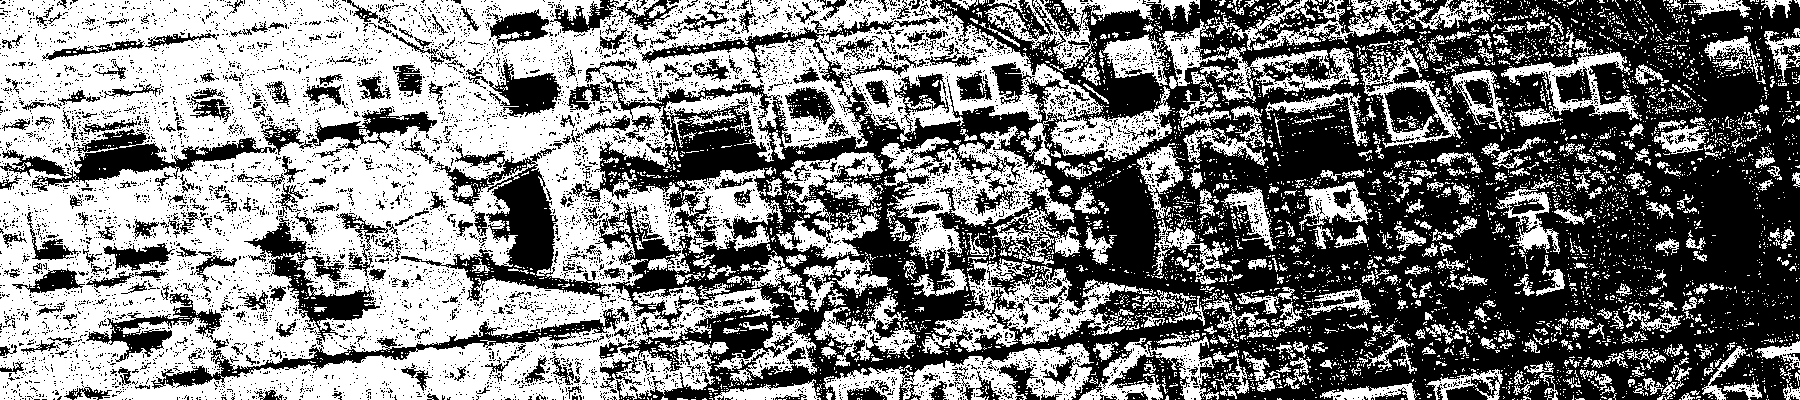

Порог 46: белые пиксели занимают 74.4% площади
Порог 70: белые пиксели занимают 49.6% площади
Порог 98: белые пиксели занимают 24.5% площади


In [5]:
masks = []
for threshold in np.quantile(x, [0.25, 0.5, 0.75]).astype(int):
    mask = x > threshold
    masks.append(mask.astype('uint8') * 255)
    print(f'Порог {threshold}: белые пиксели занимают {mask.mean():.1%} площади')
display(Image.fromarray(np.hstack(masks)))

## Вывод
Гамма меньше единицы осветлила полутона, больше единицы — затемнила. При единичной гамме контрольное сравнение даёт MSE = 0 и SSIM = 1. Чем выше порог бинаризации, тем меньшая часть снимка попадает в белую область.